# Speech processing pipeline analysis

- WER by duration
- WER by model
- Matches by type (?)
- Pipeline latencies compared:
  - Overall
  - By binned duration
  - By Whisper model
- Latency distribution
- Failed vs Correct vs Partial translations:
  - Overall
  - By Whisper model

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import json

In [2]:
df_csv = pd.read_csv("results.csv", index_col=0)

In [3]:
df_csv

,instance,reference,hypothesis,wer,overall_latency (s),listen_latency (s),filter_latency (s),normalize_latency (s),response_time (s),file_size,sample_rate,samples,duration (s),model
0,attack the alien.wav,attack the alien,attack the aim,0.333333,0.588676,0.578470,0.000004,0.009051,1.012301,481852,48000,40155,2.51,tiny
1,attack the enemy on the left.wav,attack the enemy on the left,attack the enemy on the left,0.111111,0.413839,0.389680,0.000005,0.023073,0.965416,319488,44100,57958,3.62,tiny
2,attack the enemy.wav,attack the enemy,attack the enemy,0.083333,0.994655,0.965621,0.000005,0.021808,1.982852,412732,48000,34395,2.15,tiny
3,attack the monster.wav,attack the monster,i like the monster,0.200000,0.787738,0.726267,0.000008,0.059071,1.735655,668092,48000,55675,3.48,tiny
4,attack the red monster.wav,attack the red monster,attack the red monster,0.157895,0.763427,0.717335,0.000006,0.044014,1.607689,241664,44100,43840,2.74,tiny
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,stop right here.wav,stop right here,stop attacking,0.147114,4.873177,4.867854,0.000002,0.004681,10.931337,188416,44100,34180,2.14,medium
196,stop.wav,stop,stop,0.146840,4.768009,4.766814,0.000003,0.000195,10.897759,337852,48000,28155,1.76,medium
197,use the door.wav,use the door,use the door,0.146026,4.901916,4.896635,0.000003,0.004584,11.065996,422332,48000,35195,2.20,medium
198,use the gun.wav,use the gun,use the gun,0.145221,4.979161,4.968522,0.000003,0.009640,11.171329,408892,48000,34075,2.13,medium


## WER statistics

In [4]:
df_csv.wer.describe()

count    198.000000
mean       0.191047
std        0.031287
min        0.083333
25%        0.166958
50%        0.191935
75%        0.215664
max        0.333333
Name: wer, dtype: float64

<Axes: title={'center': 'WER by duration of audio'}, xlabel='Duration (seconds)', ylabel='WER %'>

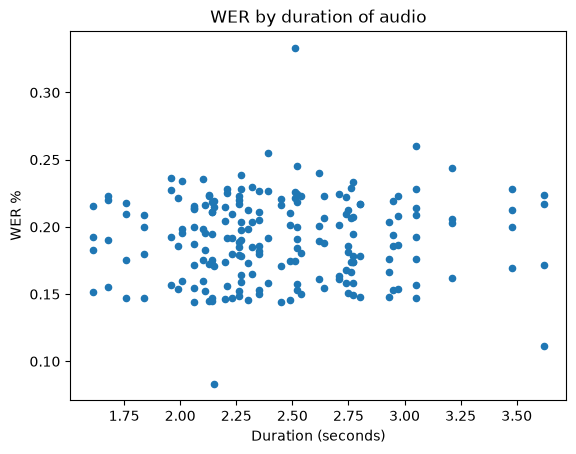

In [5]:
by_duration = df_csv.loc[:, ["wer", "duration (s)"]]

by_duration.plot.scatter(x="duration (s)", y="wer",
                         title="WER by duration of audio",
                         ylabel="WER %", xlabel="Duration (seconds)")

         wer                                                              \
       count      mean       std       min       25%       50%       75%   
model                                                                      
base    50.0  0.221547  0.008794  0.203463  0.215619  0.221960  0.227047   
medium  50.0  0.154822  0.007998  0.144161  0.147966  0.153449  0.159557   
small   50.0  0.188711  0.013173  0.170732  0.178417  0.185777  0.197925   
tiny    48.0  0.199445  0.036209  0.083333  0.185831  0.200000  0.212108   

                  
             max  
model             
base    0.244048  
medium  0.174334  
small   0.221818  
tiny    0.333333  


Text(0.5, 1.0, '')

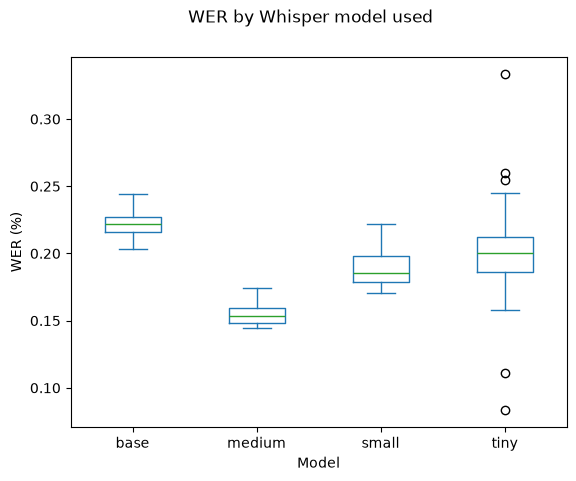

In [6]:
by_model = df_csv.loc[:, ["wer", "model"]]
print(by_model.groupby("model").describe())
axes = by_model.plot.box(by="model", title="WER by Whisper model used", xlabel="Model", ylabel="WER (%)")
axes.iloc[0].set_title("")

Text(0.5, 1.0, '')

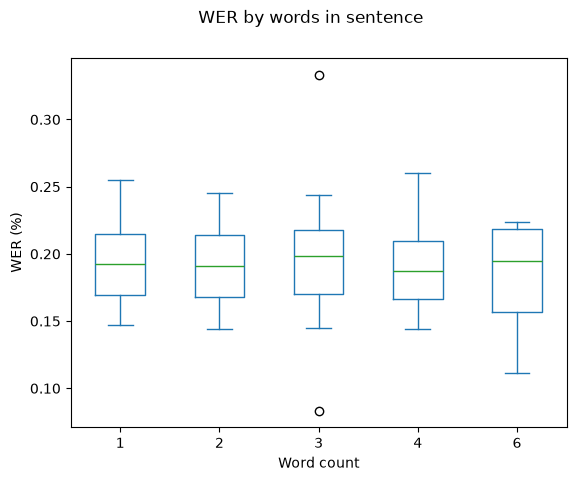

In [7]:
by_words = df_csv.loc[:, ["wer", "reference"]]
by_words["word_count"] = by_words["reference"].map(lambda sentence: len(sentence.split(" ")))

axes = by_words.plot.box(by="word_count", title="WER by words in sentence", xlabel="Word count", ylabel="WER (%)")
axes.iloc[0].set_title("")

## Transcription success

<Axes: title={'center': 'Transcription results by model'}, xlabel='Model', ylabel='Number of samples'>

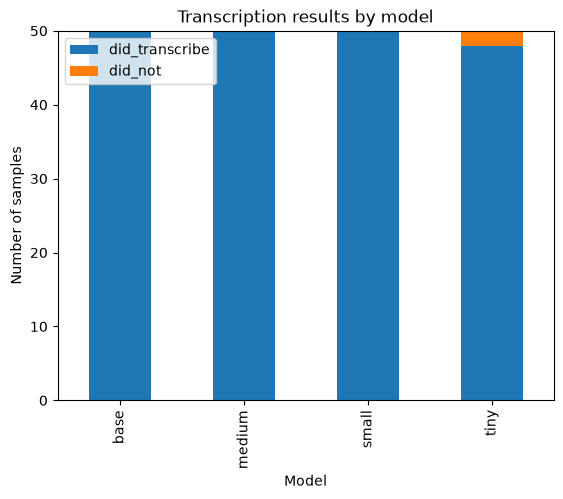

In [8]:
model_transcriptions = df_csv.loc[:, ["hypothesis", "reference", "model"]]

# Mask by transcription done
m = ~model_transcriptions["hypothesis"].isna()
model_transcriptions["did_transcribe"] = m
model_transcriptions["did_not"] = ~m

transcription_counts = model_transcriptions.groupby("model").sum().reset_index()
transcription_counts.plot.bar(
    x="model",
    y=["did_transcribe", "did_not"],
    stacked=True,
    title="Transcription results by model",
    xlabel="Model",
    ylabel="Number of samples",
 )

<Axes: title={'center': 'Transcription results by model'}, xlabel='Model', ylabel='Number of samples'>

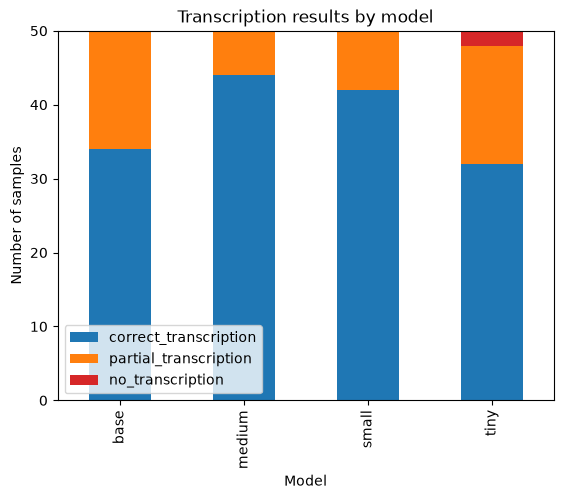

In [19]:
model_transcriptions = df_csv.loc[:, ["hypothesis", "reference", "model"]]

# Mask by transcription done
m = model_transcriptions["hypothesis"].isna()
model_transcriptions["no_transcription"] = m

# Mask by correctness of transcription
m2 = model_transcriptions["hypothesis"].eq(model_transcriptions["reference"])
model_transcriptions["correct_transcription"] = m2

# Mask for partial transcriptions
model_transcriptions["partial_transcription"] = ~m2 & ~m

detailed_transcription_counts = model_transcriptions.groupby("model").sum().reset_index()
detailed_transcription_counts.plot.bar(
    x="model",
    y=["correct_transcription", "partial_transcription", "no_transcription"],
    stacked=True,
    title="Transcription results by model",
    xlabel="Model",
    ylabel="Number of samples",
    color={"no_transcription": "tab:red", "partial_transcription": "tab:orange", "correct_transcription": "tab:blue"}
 )

In [ ]:
detailed_transcription_counts

,model,hypothesis,reference,no_transcription,correct_transcription,partial_transcription
0,base,attack dauattach the enemy on the leftattack t...,attack the alienattack the enemy on the leftat...,0,34,16
1,medium,i took the alienattack the enemy on the leftat...,attack the alienattack the enemy on the leftat...,0,44,6
2,small,attack the aiattack the enemy on the leftattac...,attack the alienattack the enemy on the leftat...,0,42,8
3,tiny,attack the aimattack the enemy on the leftatta...,attack the alienattack the enemy on the leftat...,2,32,16


medium =  0.88
small = 0.84
base = 0.68
tiny = 0.64

<Axes: title={'center': 'Correct (%) transcriptions by model and duration'}, xlabel='model', ylabel='Duration (s)'>

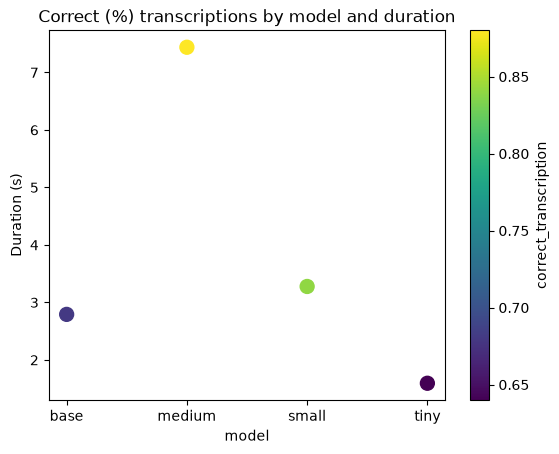

In [11]:
model_duration_correctness = df_csv.loc[:, ["hypothesis", "reference", "model", "listen_latency (s)" ]]

# Mask by transcription done
m = model_duration_correctness["hypothesis"].isna()
model_duration_correctness["no_transcription"] = m

# Mask by correctness of transcription
m2 = model_duration_correctness["hypothesis"].eq(model_duration_correctness["reference"])
model_duration_correctness["correct_transcription"] = m2

# Mask for partial transcriptions
model_duration_correctness["partial_transcription"] = ~m2 & ~m

detailed_correctness_counts = model_duration_correctness.groupby("model").mean(numeric_only=True).reset_index()

detailed_correctness_counts.plot.scatter(x="model", y="listen_latency (s)",
                                         c="correct_transcription",
                                         s=100,
                                         title="Correct (%) transcriptions by model and duration",
                                         ylabel="Duration (s)",
                                         xlabel="model")          


<Axes: title={'center': 'Partial (%) transcriptions by model and duration'}, xlabel='model', ylabel='Duration (s)'>

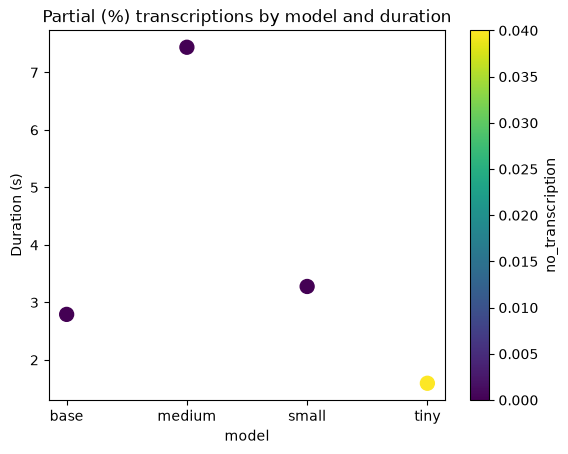

In [12]:
detailed_correctness_counts.plot.scatter(x="model", y="listen_latency (s)",
                                         c="no_transcription",
                                         s=100,
                                         title="Partial (%) transcriptions by model and duration",
                                         ylabel="Duration (s)",
                                         xlabel="model")

<Axes: title={'center': 'Failed (%) transcriptions by model and duration'}, xlabel='model', ylabel='Duration (s)'>

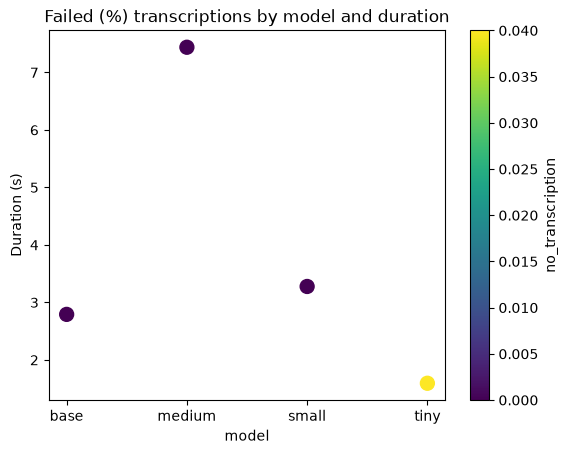

In [13]:
detailed_correctness_counts.plot.scatter(x="model", y="listen_latency (s)",
                                         c="no_transcription",
                                         s=100,
                                         title="Failed (%) transcriptions by model and duration",
                                         ylabel="Duration (s)",
                                         xlabel="model")         

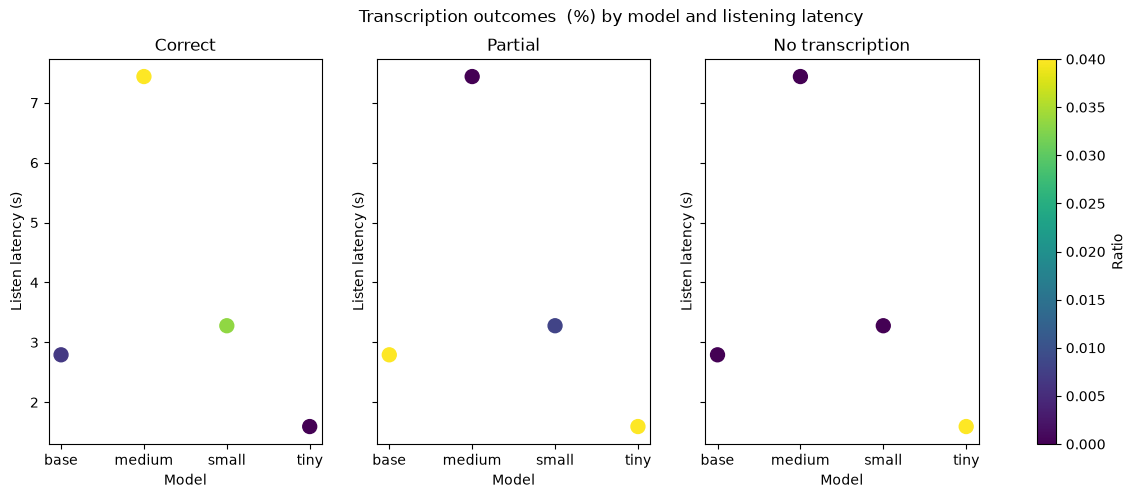

In [14]:
outcome_ratios = [
    ("correct_transcription", "Correct"),
    ("partial_transcription", "Partial"),
    ("no_transcription", "No transcription"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)

for ax, (ratio_column, title) in zip(axes, outcome_ratios):
    points = ax.scatter(
        detailed_correctness_counts["model"],
        detailed_correctness_counts["listen_latency (s)"],
        c=detailed_correctness_counts[ratio_column],
        s=100,
    )
    ax.set_title(title)
    ax.set_xlabel("Model")
    ax.set_ylabel("Listen latency (s)")

fig.colorbar(points, ax=axes, label="Ratio")
fig.suptitle("Transcription outcomes  (%) by model and listening latency")
plt.show()

## Latency and performance

Text(0.5, 1.0, '')

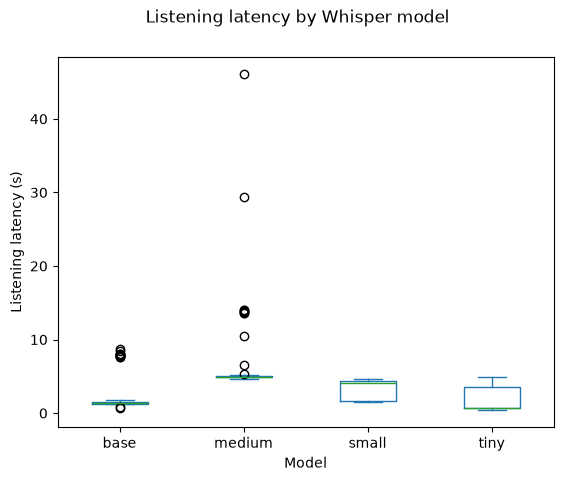

In [15]:
latency_by_model = df_csv.loc[:, ["model", "listen_latency (s)"]]

latency_by_model = df_csv.loc[:, ["model", "listen_latency (s)"]]

axes = latency_by_model.plot.box(
    by="model",
    title = "Listening latency by Whisper model",
    xlabel = "Model",
    ylabel = "Listening latency (s)",
)
axes.iloc[0].set_title("")

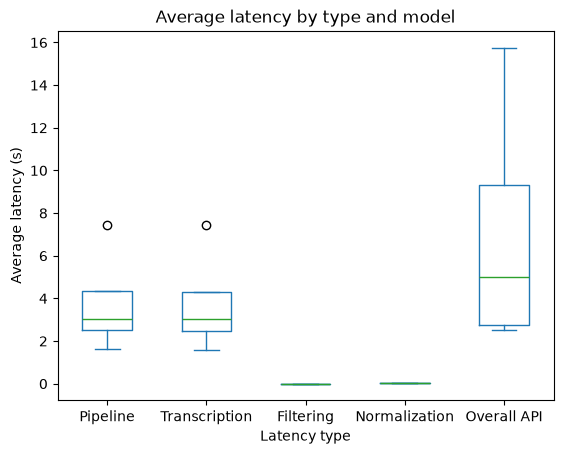

In [16]:
latency_columns = [
    "overall_latency (s)",
    "listen_latency (s)",
    "filter_latency (s)",
    "normalize_latency (s)",
    "response_time (s)",
]

average_latencies = df_csv.groupby("model")[latency_columns].mean()
average_latencies.rename(columns={
    "overall_latency (s)": "Pipeline",
    "listen_latency (s)": "Transcription",
    "filter_latency (s)": "Filtering",
    "normalize_latency (s)": "Normalization",
    "response_time (s)": "Overall API",
}, inplace=True)

average_latencies.plot.box(
    title="Average latency by type and model",
    xlabel="Latency type",
    ylabel="Average latency (s)",
)
plt.show()

In [30]:
average_latencies,
df_csv.groupby("model")[latency_columns].describe()

overall_latency (s)                                                    \
                     count      mean       std       min       25%       50%   
model                                                                          
base                  50.0  2.812800  2.801731  0.709785  1.313053  1.397484   
medium                50.0  7.453383  7.127814  4.652451  4.867319  4.966480   
small                 50.0  3.291680  1.328932  1.569299  1.639332  4.143595   
tiny                  50.0  1.615449  1.494202  0.413839  0.677210  0.718529   

                            listen_latency (s)            ...  \
             75%        max              count      mean  ...   
model                                                     ...   
base    1.547520   8.804643               50.0  2.791932  ...   
medium  5.039785  46.071702               50.0  7.437826  ...   
small   4.380641   4.694433               50.0  3.277337  ...   
tiny    3.596571   5.026839               50.0  1.594204  ...   

       normalize_latency (s)           response_time (s)             \
                         75%       max             count       mean   
model                                                                 
base                0.027287  0.069936              50.0   2.829431   
medium              0.018453  0.164915              50.0  15.755481   
small               0.015639  0.044796              50.0   7.195483   
tiny                0.028398  0.068973              50.0   2.518151   

                                                                          
              std        min        25%        50%        75%        max  
model                                                                     
base     2.802148   0.719779   1.329056   1.415348   1.559873   8.830330  
medium  10.296113  10.743026  10.961087  11.161999  12.070521  65.320248  
small    2.802027   3.522829   3.724702   8.973723   9.463334  10.182570  
tiny     1.524758   0.965416   1.565029   1.647777   4.567228   6.067727  

[4 rows x 40 columns]

## Normalization insights

In [17]:
with open("results.json", "r") as f:
    data = json.load(f)

rows = []
for instance in data:
    matches = instance["response"]["results"]["matches"]
    if matches is not None:
        for match in matches:
            rows.append(match)

columns = ["normalized", "match", "matched_by"]

df_json = pd.DataFrame(data=rows, columns=columns)
df_json


,normalized,match,matched_by
0,attack,attack,literal
1,stand,aim,embedding
2,attack,attack,literal
3,enemy,enemy,literal
4,crouch,on,embedding
...,...,...,...
393,door,door,literal
394,interact,use,literal
395,move,gun,levenshtein
396,move,do,levenshtein


<Axes: title={'center': 'Word match by method'}, xlabel='Method', ylabel='Words matched'>

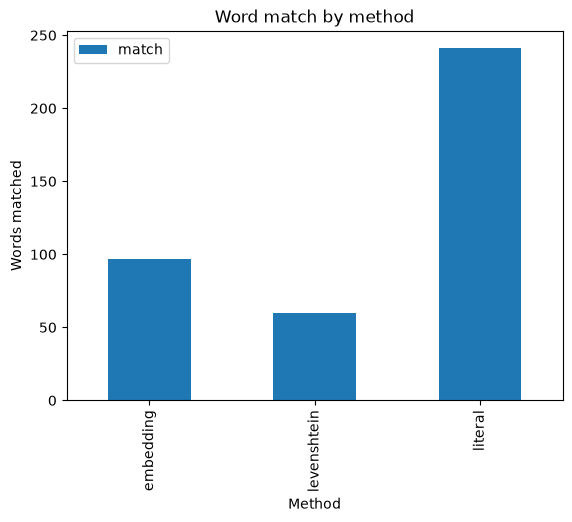

In [18]:
matched_by = df_json.groupby("matched_by").count()
matched_by.reset_index(inplace=True)

matched_by.plot.bar(x="matched_by", y="match", title="Word match by method", xlabel="Method", ylabel="Words matched")